In [1]:
# conda env 'vis2'

import sys
sys.path.append('/data/keeling/a/johntl3/b/LundstromPub2025/src')

import matplotlib.pyplot as plt
plt.style.use('dark_background')
import numpy as np
import xarray as xr
import glob
import at3d

In [2]:
version_dir = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/AT3D_output/V00'
files_def = np.sort(glob.glob(version_dir + '/default/iterations/iter*.nc'))
# files_CVM_noCVM = np.sort(glob.glob(version_dir + '/CVM/noCVM/iterations/iter*.nc'))
files_CVM_noCVM = np.sort(glob.glob(version_dir + '/CVM/darksurf_noCVM/iterations/iter*.nc'))
CVM_file = '/data/keeling/a/johntl3/b/LundstromPub2025/CAMP2Ex_RF17/intermediate_data/CVM_default.nc'

In [3]:
sensors_def, solvers_def, rte_grid_def = at3d.util.load_forward_model(files_def[-1])
sensors_noCVM, solvers_noCVM, rte_grid_noCVM = at3d.util.load_forward_model(files_CVM_noCVM[-1])

cloud_def = solvers_def[0.67].medium['cloud']
cloud_noCVM = solvers_noCVM[0.67].medium['cloud']

cvm = xr.load_dataset(CVM_file)

/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/at3d/solver.py:2337: UserWarning: Number of SHDOM grid cells with optical depth greater than 2: '61'. Max cell optical depth: '3.3198599815368652'
  warnings.warn("Number of SHDOM grid cells with optical depth greater than 2: '{}'. "
/data/keeling/a/johntl3/miniconda3/envs/vis2/lib/python3.10/site-packages/xarray/core/concat.py:500: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))


In [4]:
## Relative Bias and Difference from within the CVM
cond = cvm.cloud_volume_mask.data == 1
ext_ref = cloud_def.extinction.data[cond]
ext_tmp = cloud_noCVM.extinction.data[cond]
rel_diff = 100 * (np.sum((ext_tmp - ext_ref)**2))**0.5 / (np.sum(ext_ref)**2)**0.5
rel_bias = 100 * (np.sum(np.abs(ext_tmp)) - np.sum(np.abs(ext_ref))) / (np.sum(np.abs(ext_ref)))

print('Relative Bias: {:.2f}'.format(rel_bias))
print('Relative Diff: {:.2f}'.format(rel_diff))

Relative Bias: -42.30
Relative Diff: 1.50


In [5]:
cth_cloud = cvm.cth_mask.data.astype(bool) # R
lcl_cloud = cvm.lcl_mask.data.astype(bool) # G
sc_cloud = cvm.carved_mask.data.astype(bool) # B
cth_clear = np.logical_not(cth_cloud)
lcl_clear = np.logical_not(lcl_cloud)
sc_clear = np.logical_not(sc_cloud)

cond_cth_cloud = cth_cloud & lcl_clear & sc_clear # R
cond_lcl_cloud = lcl_cloud & cth_clear & sc_clear # G
cond_sc_cloud = sc_cloud & cth_clear & lcl_clear # B
cond_cth_clear = cth_clear & lcl_cloud & sc_cloud # GB = Teal
cond_lcl_clear = cth_cloud & lcl_clear & sc_cloud # RB = Pink
cond_sc_clear = cth_cloud & lcl_cloud & sc_clear # RG = Y
cond_cloud = cth_cloud & lcl_cloud & sc_cloud # RBG = White
cond_clear = cth_clear & lcl_clear & sc_clear # Black

cond_def_null = cloud_def.extinction.data == 0
cond_cvm_reduction = cond_def_null & cond_cloud
cond_noCVM_null = cloud_noCVM.extinction.data == 0
cond_TN = cond_def_null & cond_noCVM_null
cond_TP = np.logical_not(cond_def_null) & np.logical_not(cond_noCVM_null)
cond_FN = np.logical_not(cond_def_null) & cond_noCVM_null
cond_FP = cond_def_null & np.logical_not(cond_noCVM_null)

In [6]:
cvm['cth_cloud'] = (['x','y','z'], cond_cth_cloud)
cvm['lcl_cloud'] = (['x','y','z'], cond_lcl_cloud)
cvm['sc_cloud'] = (['x','y','z'], cond_sc_cloud)
cvm['cth_clear'] = (['x','y','z'], cond_cth_clear)
cvm['lcl_clear'] = (['x','y','z'], cond_lcl_clear)
cvm['sc_clear'] = (['x','y','z'], cond_sc_clear)
cvm['cloud'] = (['x','y','z'], cond_cloud)
cvm['clear'] = (['x','y','z'], cond_clear)

In [7]:
cloud_def_cp = cloud_def.copy(deep=True)
noCVM_cth_cloud = (cloud_def_cp.extinction.data > 0) & cvm.cth_cloud.data
noCVM_lcl_cloud = (cloud_def_cp.extinction.data > 0) & cvm.lcl_cloud.data
noCVM_sc_cloud = (cloud_def_cp.extinction.data > 0) & cvm.sc_cloud.data
noCVM_cth_clear = (cloud_def_cp.extinction.data > 0) & cvm.cth_clear.data
noCVM_lcl_clear = (cloud_def_cp.extinction.data > 0) & cvm.lcl_clear.data
noCVM_sc_clear = (cloud_def_cp.extinction.data > 0) & cvm.sc_clear.data
noCVM_cloud = (cloud_def_cp.extinction.data > 0) & cvm.cloud.data
noCVM_clear = (cloud_def_cp.extinction.data > 0) & cvm.clear.data
noCVM_cloud_vol = cloud_def_cp.extinction.data > 0
cloud_def_cp['cth_cloud'] = (['x','y','z'], noCVM_cth_cloud)
cloud_def_cp['lcl_cloud'] = (['x','y','z'], noCVM_lcl_cloud)
cloud_def_cp['sc_cloud'] = (['x','y','z'], noCVM_sc_cloud)
cloud_def_cp['cth_clear'] = (['x','y','z'], noCVM_cth_clear)
cloud_def_cp['lcl_clear'] = (['x','y','z'], noCVM_lcl_clear)
cloud_def_cp['sc_clear'] = (['x','y','z'], noCVM_sc_clear)
cloud_def_cp['cloud'] = (['x','y','z'], noCVM_cloud)
cloud_def_cp['clear'] = (['x','y','z'], noCVM_clear)
cloud_def_cp['cloud_vol'] = (['x','y','z'], noCVM_cloud_vol)

In [8]:
cloud_unc = cloud_noCVM.copy(deep=True)
noCVM_cth_cloud = (cloud_unc.extinction.data > 0) & cvm.cth_cloud.data
noCVM_lcl_cloud = (cloud_unc.extinction.data > 0) & cvm.lcl_cloud.data
noCVM_sc_cloud = (cloud_unc.extinction.data > 0) & cvm.sc_cloud.data
noCVM_cth_clear = (cloud_unc.extinction.data > 0) & cvm.cth_clear.data
noCVM_lcl_clear = (cloud_unc.extinction.data > 0) & cvm.lcl_clear.data
noCVM_sc_clear = (cloud_unc.extinction.data > 0) & cvm.sc_clear.data
noCVM_cloud = (cloud_unc.extinction.data > 0) & cvm.cloud.data
noCVM_clear = (cloud_unc.extinction.data > 0) & cvm.clear.data
noCVM_cloud_vol = cloud_unc.extinction.data > 0
cloud_unc['cth_cloud'] = (['x','y','z'], noCVM_cth_cloud)
cloud_unc['lcl_cloud'] = (['x','y','z'], noCVM_lcl_cloud)
cloud_unc['sc_cloud'] = (['x','y','z'], noCVM_sc_cloud)
cloud_unc['cth_clear'] = (['x','y','z'], noCVM_cth_clear)
cloud_unc['lcl_clear'] = (['x','y','z'], noCVM_lcl_clear)
cloud_unc['sc_clear'] = (['x','y','z'], noCVM_sc_clear)
cloud_unc['cloud'] = (['x','y','z'], noCVM_cloud)
cloud_unc['clear'] = (['x','y','z'], noCVM_clear)
cloud_unc['cloud_vol'] = (['x','y','z'], noCVM_cloud_vol)

In [9]:
n_cth_cloud = np.sum(cond_cth_cloud)
n_lcl_cloud = np.sum(cond_lcl_cloud)
n_sc_cloud = np.sum(cond_sc_cloud)
n_cth_clear = np.sum(cond_cth_clear)
n_lcl_clear = np.sum(cond_lcl_clear)
n_sc_clear = np.sum(cond_sc_clear)
n_cloud = np.sum(cond_cloud)
n_clear = np.sum(cond_clear)

print('cth cloud: {}'.format(n_cth_cloud))
print('lcl cloud: {}'.format(n_lcl_cloud))
print('sc cloud: {}'.format(n_sc_cloud))
print('cth clear: {}'.format(n_cth_clear))
print('lcl clear: {}'.format(n_lcl_clear))
print('sc clear: {}'.format(n_sc_clear))
print('cloud: {}'.format(n_cloud))
print('clear: {}'.format(n_clear))
print('-----------------------------------------')
print('total: {}'.format(n_cth_cloud + n_lcl_cloud + n_sc_cloud + n_cth_clear + n_lcl_clear + n_sc_clear + n_cloud + n_clear))

cth cloud: 2556
lcl cloud: 3364
sc cloud: 1
cth clear: 28999
lcl clear: 18531
sc clear: 1676
cloud: 12436
clear: 37
-----------------------------------------
total: 67600


In [10]:
tot = 65*65*16
print('True Negative (default = 0 & no CVM = 0): {}/{} = {:.3f}'.format(np.sum(cond_TN), tot, np.sum(cond_TN)/tot))
print('True Positive (default > 0 & no CVM > 0): {}/{} = {:.3f}'.format(np.sum(cond_TP), tot, np.sum(cond_TP)/tot))
print('False Negative (default > 0 & no CVM = 0): {}/{} = {:.3f}'.format(np.sum(cond_FN), tot, np.sum(cond_FN)/tot))
print('False Positive (default = 0 & no CVM > 0): {}/{} = {:.3f}'.format(np.sum(cond_FP), tot, np.sum(cond_FP)/tot))

True Negative (default = 0 & no CVM = 0): 42250/67600 = 0.625
True Positive (default > 0 & no CVM > 0): 3473/67600 = 0.051
False Negative (default > 0 & no CVM = 0): 1671/67600 = 0.025
False Positive (default = 0 & no CVM > 0): 20206/67600 = 0.299


FP cth cloud: 40
FP lcl cloud: 325
FP sc cloud: 0
FP cth clear: 13061
FP lcl clear: 5505
FP sc clear: 40
FP cloud: 1235
FP clear: 0
-----------------------------------------
total FP: 20206


Text(0.5, 1.0, '(Default (CVM) Extinction = 0) & (Unconstrained (no CVM) Extinction > 0)')

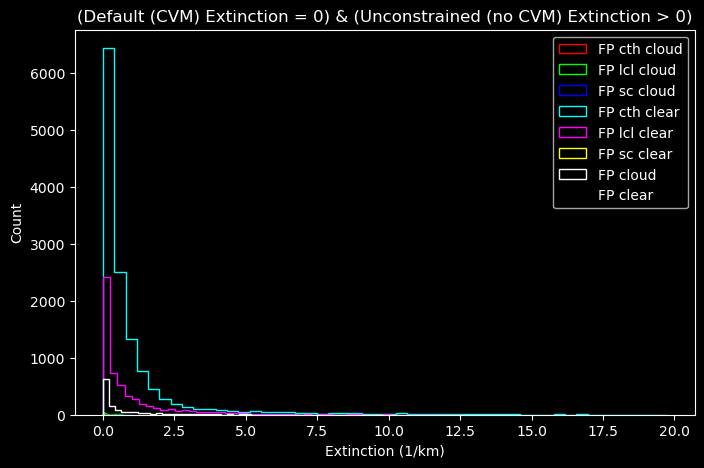

In [11]:
# What are the values of no CVM extinction for the False Positives (default = 0 & no CVM > 0)?
cond_FP_cth_cloud = cond_FP & cond_cth_cloud
cond_FP_lcl_cloud = cond_FP & cond_lcl_cloud
cond_FP_sc_cloud = cond_FP & cond_sc_cloud
cond_FP_cth_clear = cond_FP & cond_cth_clear
cond_FP_lcl_clear = cond_FP & cond_lcl_clear
cond_FP_sc_clear = cond_FP & cond_sc_clear
cond_FP_cloud = cond_FP & cond_cloud
cond_FP_clear = cond_FP & cond_clear

n_FP_cth_cloud = np.sum(cond_FP_cth_cloud)
n_FP_lcl_cloud = np.sum(cond_FP_lcl_cloud)
n_FP_sc_cloud = np.sum(cond_FP_sc_cloud)
n_FP_cth_clear = np.sum(cond_FP_cth_clear)
n_FP_lcl_clear = np.sum(cond_FP_lcl_clear)
n_FP_sc_clear = np.sum(cond_FP_sc_clear)
n_FP_cloud = np.sum(cond_FP_cloud)
n_FP_clear = np.sum(cond_FP_clear)

print('FP cth cloud: {}'.format(n_FP_cth_cloud))
print('FP lcl cloud: {}'.format(n_FP_lcl_cloud))
print('FP sc cloud: {}'.format(n_FP_sc_cloud))
print('FP cth clear: {}'.format(n_FP_cth_clear))
print('FP lcl clear: {}'.format(n_FP_lcl_clear))
print('FP sc clear: {}'.format(n_FP_sc_clear))
print('FP cloud: {}'.format(n_FP_cloud))
print('FP clear: {}'.format(n_FP_clear))
print('-----------------------------------------')
print('total FP: {}'.format(n_FP_cth_cloud + n_FP_lcl_cloud + n_FP_sc_cloud + n_FP_cth_clear + n_FP_lcl_clear + n_FP_sc_clear + n_FP_cloud + n_FP_clear))

ext_FP_cth_cloud = cloud_noCVM.extinction.data[cond_FP_cth_cloud]
ext_FP_lcl_cloud = cloud_noCVM.extinction.data[cond_FP_lcl_cloud]
ext_FP_sc_cloud = cloud_noCVM.extinction.data[cond_FP_sc_cloud]
ext_FP_cth_clear = cloud_noCVM.extinction.data[cond_FP_cth_clear]
ext_FP_lcl_clear = cloud_noCVM.extinction.data[cond_FP_lcl_clear]
ext_FP_sc_clear = cloud_noCVM.extinction.data[cond_FP_sc_clear]
ext_FP_cloud = cloud_noCVM.extinction.data[cond_FP_cloud]
ext_FP_clear = cloud_noCVM.extinction.data[cond_FP_clear]

f, ax = plt.subplots(1, 1, figsize=(8,5))
bins = 50
ax.hist(ext_FP_cth_cloud, histtype='step', bins=bins, color=[1, 0, 0], label='FP cth cloud')
ax.hist(ext_FP_lcl_cloud, histtype='step', bins=bins, color=[0, 1, 0], label='FP lcl cloud')
ax.hist(ext_FP_sc_cloud, histtype='step', bins=bins, color=[0, 0, 1], label='FP sc cloud')
ax.hist(ext_FP_cth_clear, histtype='step', bins=bins, color=[0, 1, 1], label='FP cth clear')
ax.hist(ext_FP_lcl_clear, histtype='step', bins=bins, color=[1, 0, 1], label='FP lcl clear')
ax.hist(ext_FP_sc_clear, histtype='step', bins=bins, color=[1, 1, 0], label='FP sc clear')
ax.hist(ext_FP_cloud, histtype='step', bins=bins, color=[1, 1, 1], label='FP cloud')
ax.hist(ext_FP_clear, histtype='step', bins=bins, color=[0, 0, 0], label='FP clear')
ax.legend()
ax.set_xlabel('Extinction (1/km)')
ax.set_ylabel('Count')
ax.set_title('(Default (CVM) Extinction = 0) & (Unconstrained (no CVM) Extinction > 0)')

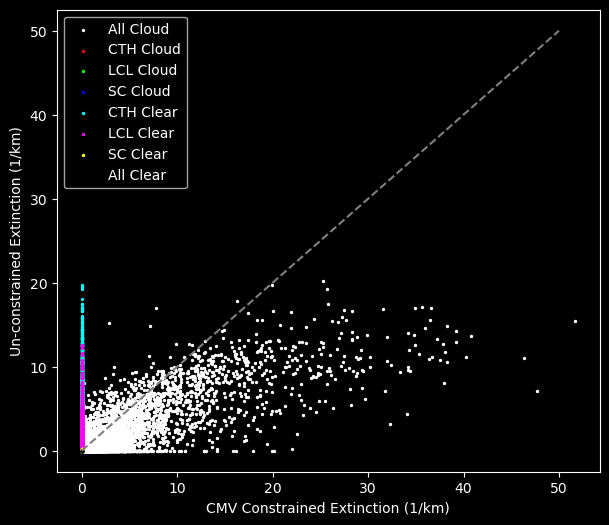

In [12]:
plt.style.use('dark_background')
f, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.plot([0, 50], [0, 50], color='gray', linestyle='--', linewidth=1.5)  # 1:1 line
# ax.scatter(np.ravel(cloud_def.extinction.data), np.ravel(cloud_noCVM.extinction.data), c=cvm.rbg_mask.data.reshape(65*65*16, 3), s=2)
s = 2
ax.scatter(np.ravel(cloud_def.extinction.data[cond_cloud]), np.ravel(cloud_noCVM.extinction.data[cond_cloud]), color=[1, 1, 1, 1], s=s, label='All Cloud')
ax.scatter(np.ravel(cloud_def.extinction.data[cond_cth_cloud]), np.ravel(cloud_noCVM.extinction.data[cond_cth_cloud]), color=[1, 0, 0, 1], s=s, label='CTH Cloud')
ax.scatter(np.ravel(cloud_def.extinction.data[cond_lcl_cloud]), np.ravel(cloud_noCVM.extinction.data[cond_lcl_cloud]), color=[0, 1, 0, 1], s=s, label='LCL Cloud')
ax.scatter(np.ravel(cloud_def.extinction.data[cond_sc_cloud]), np.ravel(cloud_noCVM.extinction.data[cond_sc_cloud]), color=[0, 0, 1, 1], s=s, label='SC Cloud')
ax.scatter(np.ravel(cloud_def.extinction.data[cond_cth_clear]), np.ravel(cloud_noCVM.extinction.data[cond_cth_clear]), color=[0, 1, 1, 1], s=s, label='CTH Clear')
ax.scatter(np.ravel(cloud_def.extinction.data[cond_lcl_clear]), np.ravel(cloud_noCVM.extinction.data[cond_lcl_clear]), color=[1, 0, 1, 1], s=s, label='LCL Clear')
ax.scatter(np.ravel(cloud_def.extinction.data[cond_sc_clear]), np.ravel(cloud_noCVM.extinction.data[cond_sc_clear]), color=[1, 1, 0, 1], s=s, label='SC Clear')
ax.scatter(np.ravel(cloud_def.extinction.data[cond_clear]), np.ravel(cloud_noCVM.extinction.data[cond_clear]), color=[0, 0, 0, 1], s=s, label='All Clear')

ax.set_xlabel('CMV Constrained Extinction (1/km)')
ax.set_ylabel('Un-constrained Extinction (1/km)')
# ax.grid()
ax.legend()

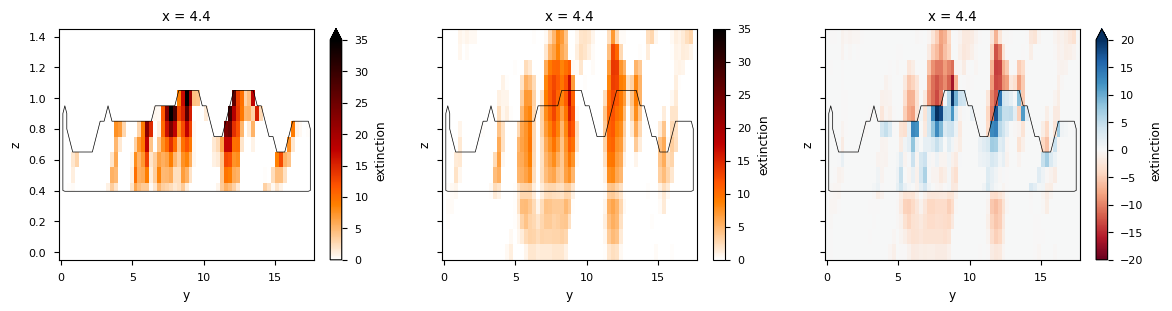

In [13]:
ext_cmap = 'gist_heat_r'
x = 4.4
vmax = 35
plt.style.use('default')
plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
cloud_def.sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[0], vmin=0, vmax=vmax, cmap=ext_cmap)
cloud_noCVM.sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[1], vmin=0, vmax=vmax, cmap=ext_cmap)
(cloud_def.extinction - cloud_noCVM.extinction).sel(x=x, method='nearest').plot(y='z', ax=ax[2], vmin=-20, vmax=20, cmap='RdBu')
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[0], colors='black', linewidths=0.5)
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[1], colors='black', linewidths=0.5)
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[2], colors='black', linewidths=0.5)

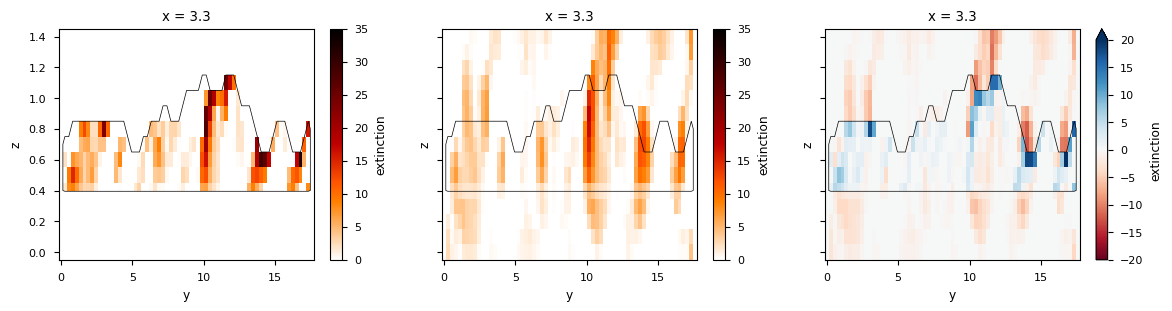

In [14]:
x = 3.3
vmax = 35
plt.style.use('default')
plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
cloud_def.sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[0], vmin=0, vmax=vmax, cmap=ext_cmap)
cloud_noCVM.sel(x=x, method='nearest').extinction.plot(y='z', ax=ax[1], vmin=0, vmax=vmax, cmap=ext_cmap)
(cloud_def.extinction - cloud_noCVM.extinction).sel(x=x, method='nearest').plot(y='z', ax=ax[2], vmin=-20, vmax=20, cmap='RdBu')
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[0], colors='black', linewidths=0.5)
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[1], colors='black', linewidths=0.5)
cvm.sel(x=x, method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[2], colors='black', linewidths=0.5)

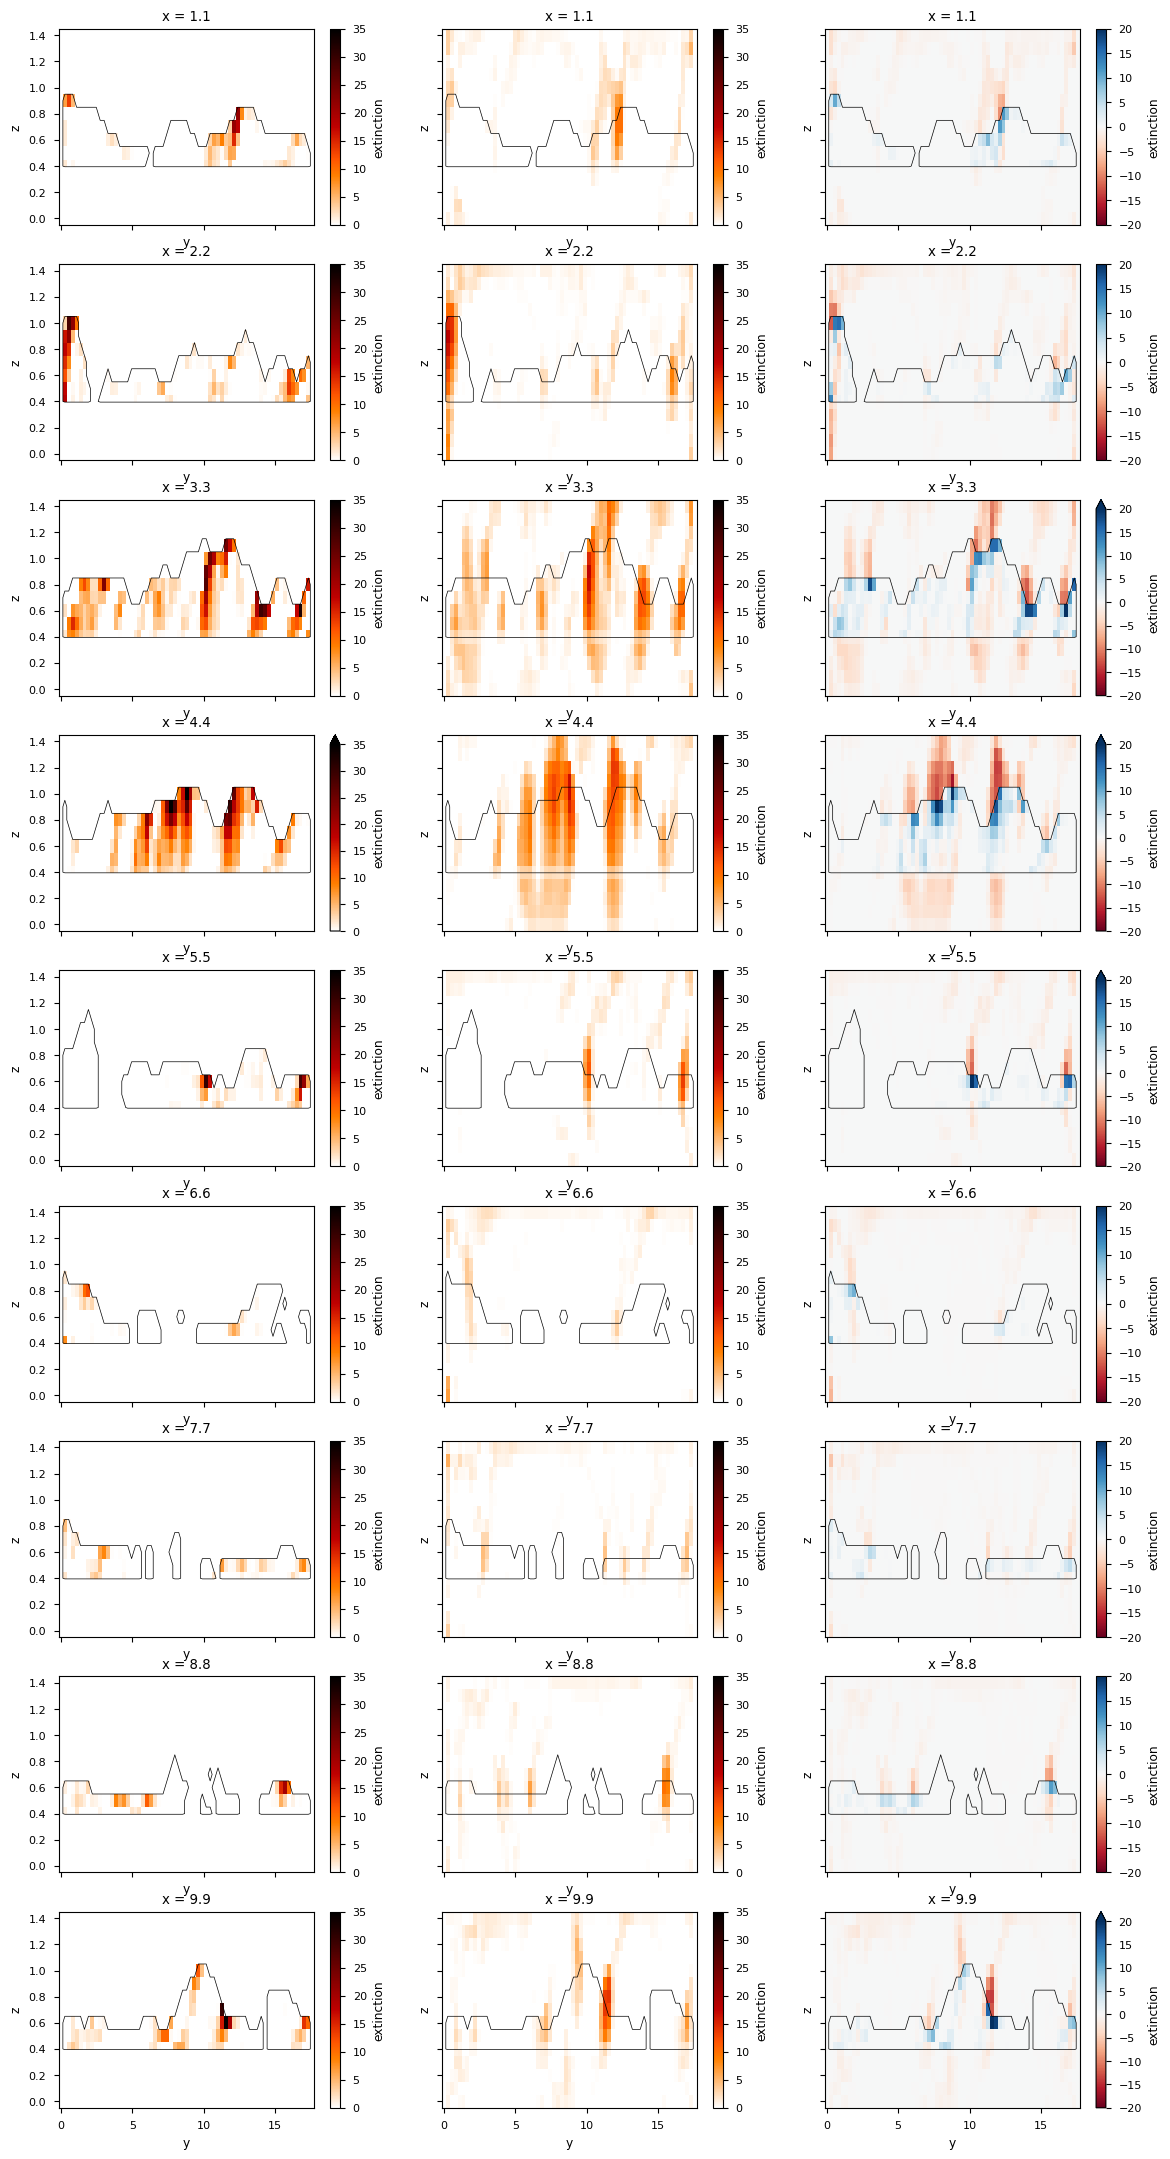

In [15]:
x = [1.1, 2.2, 3.3, 4.4, 5.5, 6.6, 7.7, 8.8, 9.9]
vmax = 35
plt.style.use('default')
plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(len(x), 3, figsize=(14, 3*len(x)), sharex=True, sharey=True)
for i in range(len(x)):
    cloud_def.sel(x=x[i], method='nearest').extinction.plot(y='z', ax=ax[i, 0], vmin=0, vmax=vmax, cmap=ext_cmap)
    cloud_noCVM.sel(x=x[i], method='nearest').extinction.plot(y='z', ax=ax[i, 1], vmin=0, vmax=vmax, cmap=ext_cmap)
    (cloud_def.extinction - cloud_noCVM.extinction).sel(x=x[i], method='nearest').plot(y='z', ax=ax[i, 2], vmin=-20, vmax=20, cmap='RdBu')
    cvm.sel(x=x[i], method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[i, 0], colors='black', linewidths=0.5)
    cvm.sel(x=x[i], method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[i, 1], colors='black', linewidths=0.5)
    cvm.sel(x=x[i], method='nearest').cloud_volume_mask.plot.contour(y='z', levels=1, ax=ax[i, 2], colors='black', linewidths=0.5)

In [16]:
cloud_def['tau'] = cloud_def.extinction.integrate('z')
cloud_noCVM['tau'] = cloud_noCVM.extinction.integrate('z')

Text(0.5, 1.0, 'Difference\nConstrained-Unconstrained')

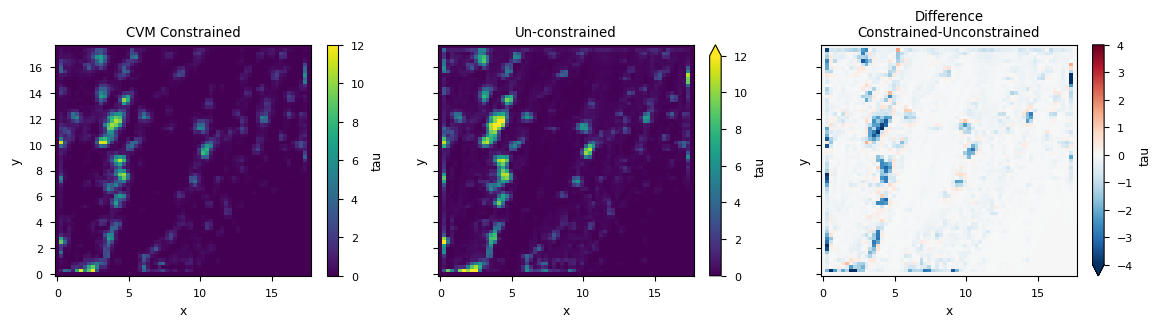

In [17]:
tau_cmap = 'viridis'
vmax = 12
plt.style.use('default')
plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(1, 3, figsize=(14, 3), sharey=True)
cloud_def.tau.plot(y='y', ax=ax[0], vmin=0, vmax=vmax, cmap=tau_cmap)
cloud_noCVM.tau.plot(y='y', ax=ax[1], vmin=0, vmax=vmax, cmap=tau_cmap)
(cloud_def.tau - cloud_noCVM.tau).plot(y='y', ax=ax[2], vmin=-4, vmax=4, cmap='RdBu_r')
ax[0].set_title('CVM Constrained')
ax[1].set_title('Un-constrained')
ax[2].set_title('Difference\nConstrained-Unconstrained')

Text(0, 0.5, 'Un-constrained $\\tau$')

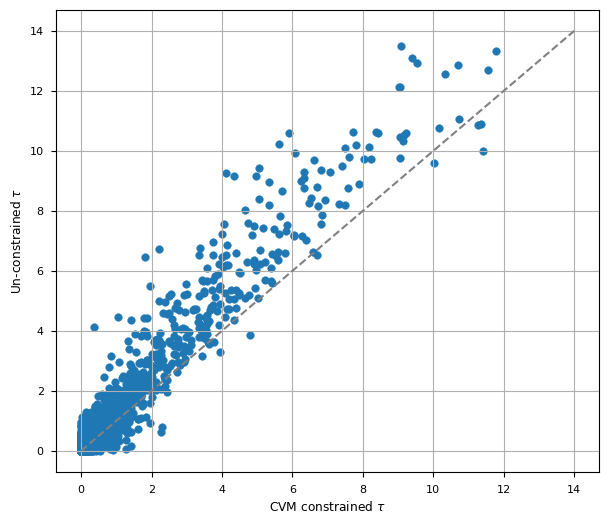

In [18]:
plt.style.use('seaborn-v0_8-paper')
f, ax = plt.subplots(1, 1, figsize=(7, 6))
ax.scatter(cloud_def.tau.data, cloud_noCVM.tau.data)
ax.plot([0, 14], [0, 14], color='gray', linestyle='--', linewidth=1.5)  # 1:1 line
ax.grid()
ax.set_xlabel(r'CVM constrained $\tau$')
ax.set_ylabel(r'Un-constrained $\tau$')